# Sightline: the results

Every measured value in this notebook is read from the JSON reports committed under `reports/`:

- `reports/runs/` holds one report per trained run, written by `sightline eval`;
- `reports/summary.json` combines them over seeds (`sightline report`);
- `reports/leakage.json` is the leakage analysis (`sightline leakage`);
- `reports/legacy.json` scores the standard-recipe PilotNet (`sightline legacy`);
- `reports/export.json` records the two models the browser page runs (`sightline site-data`).

Nothing is computed again from frames or weights, so the notebook runs on a fresh clone without the
dataset. The text cells describe; every number is printed by a code cell. The ratios, counts and
seed-by-seed comparisons printed beside the measured values are computed from them. The cutoffs the
evaluation scores with, the edges of the steering regimes, the smallest angle counted in the sign agreement
and the tolerances of the shares of frames within them, are recorded in `reports/summary.json` too.
Settings the reports do not record come from the code that produced them: the recipe's learning-rate
schedule and checkpoint rule are those of `sightline.train`, the schedule checked against its source.

Errors are mean absolute errors (MAE) of the steering-wheel angle in degrees. "Always straight ahead" is
the predictor that answers zero degrees for every frame: the bar any steering model has to clear.
"Skill" is the share of that predictor's error a model removes, one minus their ratio, so it is zero for
a model no better than steering straight ahead and negative for a worse one.

In [1]:
import importlib.util
import io
import json
import os
import sys
from collections import Counter
from pathlib import Path

from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure

# work from the repository root, wherever the notebook was opened
root = Path.cwd()
while not (root / "reports" / "summary.json").is_file():
    if root == root.parent:
        raise FileNotFoundError("open this notebook inside the sightline repository (no reports/summary.json found)")
    root = root.parent
os.chdir(root)
try:
    import sightline  # noqa: F401
except ModuleNotFoundError:  # not installed: use the source tree beside the reports
    sys.path.insert(0, str(root / "src"))
from sightline import figures
from sightline.evaluate import within_key


def load(path):
    return json.loads(Path(path).read_text())


summary = load("reports/summary.json")
runs = {path.stem: load(path) for path in sorted(Path("reports/runs").glob("*.json"))}
leakage = load("reports/leakage.json")
legacy = load("reports/legacy.json")
export = load("reports/export.json")
cutoffs = summary["cutoffs"]  # the evaluation's cutoffs, as the summary records them
assert sorted(runs) == summary["runs"], "the summary and the run reports name different runs"
(TRAIN_DRIVE,) = {r["drive"] for r in runs.values()}
(CROSS_DRIVE,) = {r["cross_drive"]["drive"] for r in runs.values()}
RUNG = {e["protocol"]: e["rung"] for e in summary["ladder"]["sightlinenet"] if e["split"] == "test"}
LABEL = figures.MODEL_LABELS


def report(model, protocol, seed):
    return runs[f"{TRAIN_DRIVE}_{model}_{protocol}_s{seed}"]


def group(model, protocol):
    return summary["groups"][f"{model}/{protocol}"]


def members(model, protocol):
    return [report(model, protocol, seed) for seed in group(model, protocol)["seeds"]]


def pm(stat, digits=2):
    # mean and sample standard deviation over seeds
    return f"{stat['mean']:.{digits}f} ± {stat['sd']:.{digits}f}"


def per_seed(stat, digits=2):
    return ", ".join(f"{value:.{digits}f}" for value in stat["values"])


def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + " --- |" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def show(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=fig.dpi, facecolor=fig.get_facecolor(), metadata={"Software": None})
    display(Image(buffer.getvalue()))


# the reports record the starting learning rate; its schedule is the training code's
assert "CosineAnnealingLR(" in Path(importlib.util.find_spec("sightline.train").origin).read_text()
cfg = summary["train_config"]
print(f"{len(runs)} run reports: trained on {TRAIN_DRIVE}, another day is {CROSS_DRIVE}")
print(f"trained at commit {', '.join(c[:7] for c in summary['code_versions']['train'])} on "
      + ", ".join(f"{device} ({count} runs)" for device, count in Counter(r["train_device"] for r in runs.values()).items())
      + f"; evaluated at commit {', '.join(c[:7] for c in summary['code_versions']['eval'])} on the {summary['device']}")
print("libraries: " + ", ".join(f"{name} {version}" for name, version in sorted(summary["versions"].items())))
print(f"recipe: {cfg['epochs']} epochs, batch {cfg['batch_size']}, "
      f"learning rate {cfg['lr']:g} at the start, on the cosine schedule of sightline.train, "
      f"weight decay {cfg['weight_decay']:g}, "
      + ("no early stopping" if cfg["patience"] == 0 else f"early stopping after {cfg['patience']} epochs")
      + "; sightline.train keeps the checkpoint with the lowest validation error")
for model, recipe in cfg["models"].items():
    first = report(model, "blocked", 0)
    frames = "frames " + " and ".join(["t"] + [f"t-{lag}" for lag in first["frame_lags"]]) if first["frame_lags"] else "frame t alone"
    print(f"  {LABEL[model]}: {frames}, {first['n_params']:,} parameters, "
          f"{recipe['augment']} augmentation, dropout {recipe['dropout']:g}, seeds {group(model, 'blocked')['seeds']}")

21 run reports: trained on drive2018, another day is drive2017
trained at commit 493b3b8 on mps (21 runs); evaluated at commit ed7ca37 on the cpu
libraries: numpy 2.5.1, python 3.12.13, torch 2.13.0
recipe: 20 epochs, batch 128, learning rate 0.0003 at the start, on the cosine schedule of sightline.train, weight decay 0.0001, no early stopping; sightline.train keeps the checkpoint with the lowest validation error
  PilotNet: frame t alone, 1,595,511 parameters, standard augmentation, dropout 0.2, seeds [0, 1, 2]
  SightlineNet: frames t and t-2, 289,289 parameters, strong augmentation, dropout 0.3, seeds [0, 1, 2]
  SightlineNet, single frame: frame t alone, 287,489 parameters, strong augmentation, dropout 0.3, seeds [0, 1, 2]


## Four ways to test a steering model

Every run trains on `drive2018` and is tested in up to four ways, each further from the training frames than
the one before.

- **Shuffled**: the frames are shuffled and dealt into training, validation and test sets. Almost every
  test frame then has a training frame a fraction of a second away, showing the same road at the same
  steering angle. This is the standard failure mode, reproduced on purpose so it can be measured.
- **Blocked**: the drive is cut into blocks of consecutive frames dealt out in a fixed repeating pattern,
  and the frames on both sides of every boundary between a training block and an evaluation block are
  dropped. Training and test see the same mix of roads, but no test frame is close in time to a training
  frame. This is the honest headline.
- **Later in the drive**: train on the start of the drive and test on its end, with the same gap. This
  adds a change of road to the test, because the end of the drive is calmer driving than its middle
  (`01-data-and-leakage.ipynb` draws the profile).
- **Another day**: the models are scored on `drive2017`, recorded on a different day.

The table gives each split's size and how far its test frames sit from the nearest training frame, which
grows from the shuffled split to the later-in-the-drive split. Another day is a different drive, so there
is no such distance to give.

In [2]:
gaps = leakage["gaps"]
split_seed = leakage["seed"]
rows = []
for protocol in ("leaky", "blocked", "forward"):
    splits = report("sightlinenet", protocol, split_seed)["splits"]
    gap = gaps[protocol]["test"]
    rows.append([RUNG[protocol], f"{splits['train_n']:,}", f"{splits['val_n']:,}", f"{splits['test_n']:,}",
                 f"{gap['min_frames']:,}", f"{gap['median_frames']:,g}", f"{gap['frac_within_1']:.1%}"])
table(["split", "training frames", "validation frames", "test frames", "nearest training frame: closest case (frames)",
       "median (frames)", "test frames next to a training frame"], rows)

medians = [gaps[protocol]["test"]["median_frames"] for protocol in ("leaky", "blocked", "forward")]
assert all(a < b for a, b in zip(medians, medians[1:])), "each split should sit further from training than the one before"
print("median distance to the nearest training frame, from the shuffled split to the later-in-the-drive split: "
      + ", ".join(f"{m:,g}" for m in medians) + " frames; another day is a different drive")

splits = report("sightlinenet", "blocked", split_seed)["splits"]
dt = summary["drives"][TRAIN_DRIVE]["median_dt_s"]
gap = 2 * splits["firewall"] + 1
print(f"blocked: blocks of {splits['block']:,} frames; {splits['firewall']} frames dropped on each side of every "
      f"training/evaluation boundary, so every evaluation frame is at least {gap} frames "
      f"({gap * dt:.1f} s at the median frame interval of {1000 * dt:.1f} ms) from a training frame")
(cross,) = {r["cross_drive"]["n"] for r in runs.values()}
frames = summary["drives"][CROSS_DRIVE]["frames"]
print(f"another day: {cross:,} of the {frames:,} frames of {CROSS_DRIVE}, all but the first {frames - cross}, "
      "so every model has its earlier frames")
# every run of a split, whatever its model or seed, deals the same numbers of frames
counts = []
for protocol in ("leaky", "blocked", "forward"):
    in_protocol = [r for r in runs.values() if r["protocol"] == protocol]
    dealt = {tuple(r["splits"][k] for k in ("train_n", "val_n", "test_n")) for r in in_protocol}
    assert len(dealt) == 1, f"the {RUNG[protocol]} runs deal different numbers of frames: {sorted(dealt)}"
    counts.append(f"{RUNG[protocol]} in {len(in_protocol)} runs")
print(f"the shuffled split above is seed {split_seed}'s; every run of a split deals the same numbers of frames: "
      + ", ".join(counts))

| split | training frames | validation frames | test frames | nearest training frame: closest case (frames) | median (frames) | test frames next to a training frame |
| --- | --- | --- | --- | --- | --- | --- |
| shuffled | 44,677 | 9,574 | 9,574 | 1 | 1 | 90.9% |
| blocked | 39,825 | 6,000 | 6,000 | 501 | 750.5 | 0.0% |
| later in the drive | 44,427 | 9,074 | 9,324 | 10,075 | 14,736.5 | 0.0% |

median distance to the nearest training frame, from the shuffled split to the later-in-the-drive split: 1, 750.5, 14,736.5 frames; another day is a different drive
blocked: blocks of 1,500 frames; 250 frames dropped on each side of every training/evaluation boundary, so every evaluation frame is at least 501 frames (28.6 s at the median frame interval of 57.0 ms) from a training frame
another day: 45,404 of the 45,406 frames of drive2017, all but the first 2, so every model has its earlier frames
the shuffled split above is seed 0's; every run of a split deals the same numbers of frames: shuffled in 6 runs, blocked in 9 runs, later in the drive in 6 runs


## The shipped model is chosen on validation

The browser page runs one SightlineNet trained on the blocked split. Which seed ships is decided by the
validation error alone; test and another-day scores take no part in the choice. The table shows them all,
including where the choice would have been different on test.

In [3]:
shipped = summary["shipped"]
g = group(shipped["model"], shipped["protocol"])
rows = [[seed, f"{r['val']['model']['mae_deg']:.3f}", f"{r['test']['model']['mae_deg']:.3f}",
         f"{r['cross_drive']['model']['mae_deg']:.3f}", "shipped" if r["run"] == shipped["run"] else ""]
        for seed, r in zip(g["seeds"], members(shipped["model"], shipped["protocol"]))]
table(["seed", "validation MAE", "test MAE", "another-day MAE", ""], rows)
best_on_test = g["seeds"][min(range(len(g["seeds"])), key=lambda i: g["test_mae_deg"]["values"][i])]
print(f"shipped: {shipped['run']}, the lowest {shipped['selected_by']}; "
      f"its shuffled-split twin (same model and seed): {summary['twin']['run']}")
print(f"the lowest test MAE belongs to seed {best_on_test}"
      + (", the shipped one" if best_on_test == shipped["seed"] else ", not the shipped one; test scores never choose"))

| seed | validation MAE | test MAE | another-day MAE |  |
| --- | --- | --- | --- | --- |
| 0 | 8.427 | 10.973 | 12.140 |  |
| 1 | 7.500 | 9.619 | 10.010 |  |
| 2 | 7.153 | 10.123 | 9.771 | shipped |

shipped: drive2018_sightlinenet_blocked_s2, the lowest val_mae_deg; its shuffled-split twin (same model and seed): drive2018_sightlinenet_leaky_s2
the lowest test MAE belongs to seed 1, not the shipped one; test scores never choose


## The generalisation ladder

Each rung moves the test further from the training frames; that is all the order means. The frames
themselves differ from rung to rung, and so does how much of them is easy straight driving, so the raw
errors of two rungs cannot be compared with each other. Compare each error with what always steering
straight ahead scores on the same frames; the skill, one minus their ratio, does exactly that. The table
gives each model's error on every rung as the mean and sample standard deviation over seeds, then each
seed's value, the error of always steering straight ahead, the skill, and how many seeds beat steering
straight ahead. Straight ahead is scored on each run's own test frames. On every rung but the shuffled
one the seeds share those frames; each shuffled seed deals a test set of its own, so on that rung the
column gives the mean over the seeds' test sets, and the lines below the table give each seed's value.
The single frame SightlineNet was trained on the blocked split only, so it has two rungs.

| model | rung | MAE, mean ± sd | per seed | always straight ahead | skill, mean ± sd | seeds better than straight ahead |
| --- | --- | --- | --- | --- | --- | --- |
| PilotNet | shuffled | 4.01 ± 0.21 | 3.77, 4.07, 4.18 | 13.14 | 0.695 ± 0.010 | 3 of 3 |
| PilotNet | blocked | 12.94 ± 0.16 | 13.02, 13.04, 12.76 | 17.48 | 0.260 ± 0.009 | 3 of 3 |
| PilotNet | later in the drive | 13.63 ± 4.14 | 15.07, 8.96, 16.86 | 9.41 | -0.449 ± 0.440 | 1 of 3 |
| PilotNet | another day | 19.28 ± 1.22 | 20.51, 19.28, 18.07 | 15.52 | -0.242 ± 0.079 | 0 of 3 |
| SightlineNet | shuffled | 2.90 ± 0.09 | 2.83, 2.89, 3.00 | 13.14 | 0.779 ± 0.000 | 3 of 3 |
| SightlineNet | blocked | 10.24 ± 0.68 | 10.97, 9.62, 10.12 | 17.48 | 0.414 ± 0.039 | 3 of 3 |
| SightlineNet | later in the drive | 6.18 ± 0.25 | 6.07, 6.01, 6.46 | 9.41 | 0.343 ± 0.026 | 3 of 3 |
| SightlineNet | another day | 10.64 ± 1.30 | 12.14, 10.01, 9.77 | 15.52 | 0.315 ± 0.084 | 3 of 3 |
| SightlineNet, single frame | blocked | 11.42 ± 0.54 | 11.19, 11.03, 12.03 | 17.48 | 0.347 ± 0.031 | 3 of 3 |
| SightlineNet, single frame | another day | 15.23 ± 0.66 | 14.47, 15.57, 15.65 | 15.52 | 0.019 ± 0.042 | 1 of 3 |

PilotNet: mean error below always straight ahead on shuffled, blocked; above it on later in the drive, another day
SightlineNet: mean error below always straight ahead on shuffled, blocked, later in the drive, another day
SightlineNet, single frame: mean error below always straight ahead on blocked, another day
PilotNet: skill on each rung, shuffled 0.695, blocked 0.260, later in the drive -0.449, another day -0.242
SightlineNet: skill on each rung, shuffled 0.779, blocked 0.414, later in the drive 0.343, another day 0.315
SightlineNet, single frame: skill on each rung, blocked 0.347, another day 0.019
PilotNet, shuffled rung: always straight ahead on each seed's own test frames 12.81, 13.02, 13.58, mean 13.14
SightlineNet, shuffled rung: always straight ahead on each seed's own test frames 12.81, 13.02, 13.58, mean 13.14


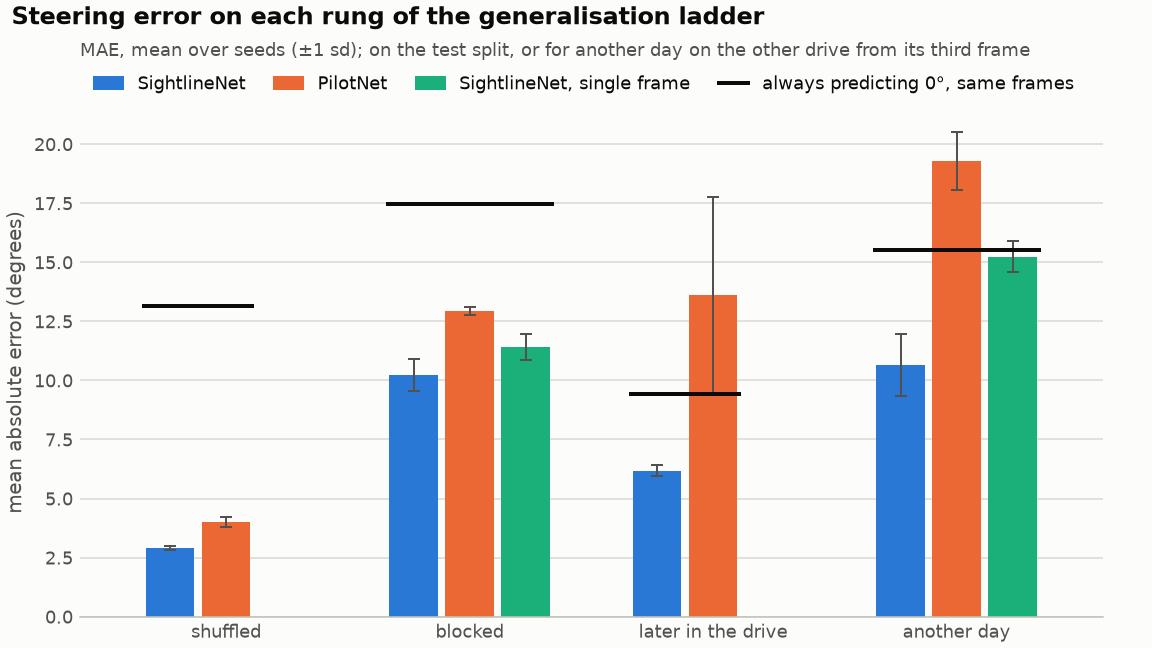

In [4]:
rows, verdicts, skills = [], {}, {}
for model, ladder in summary["ladder"].items():
    for entry in ladder:
        g = group(model, entry["protocol"])
        split = "test" if entry["split"] == "test" else "cross_drive"
        skill = g["test_skill"] if split == "test" else g["cross_skill"]
        scored = members(model, entry["protocol"])
        # skill: one minus the model's error over what steering straight ahead scores on the same frames
        assert all(abs(r[split]["skill_vs_zero"] - (1 - r[split]["model"]["mae_deg"] / r[split]["baselines"]["zero"]["mae_deg"])) < 1e-9
                   for r in scored)
        wins = sum(r[split]["model"]["mae_deg"] < r[split]["baselines"]["zero"]["mae_deg"] for r in scored)
        rows.append([LABEL[model], entry["rung"], pm(entry["mae_deg"]), per_seed(entry["mae_deg"]),
                     f"{entry['zero_mae_deg']:.2f}", pm(skill, 3), f"{wins} of {len(entry['seeds'])}"])
        verdicts.setdefault(model, {})[entry["rung"]] = (entry["mae_deg"]["mean"] < entry["zero_mae_deg"], wins, len(entry["seeds"]))
        skills.setdefault(model, {})[entry["rung"]] = skill["mean"]
table(["model", "rung", "MAE, mean ± sd", "per seed", "always straight ahead", "skill, mean ± sd",
       "seeds better than straight ahead"], rows)
for model, results in verdicts.items():
    better = [rung for rung, (ok, _, _) in results.items() if ok]
    worse = [rung for rung, (ok, _, _) in results.items() if not ok]
    print(f"{LABEL[model]}: mean error below always straight ahead on {', '.join(better) or 'no rung'}"
          + (f"; above it on {', '.join(worse)}" if worse else ""))
for model, by_rung in skills.items():
    print(f"{LABEL[model]}: skill on each rung, " + ", ".join(f"{rung} {value:.3f}" for rung, value in by_rung.items()))
# the shuffled rung's straight-ahead figure is a mean over the seeds' own test sets: each seed's value
for model, ladder in summary["ladder"].items():
    for entry in (e for e in ladder if e["protocol"] == "leaky"):
        zeros = [r["test"]["baselines"]["zero"]["mae_deg"] for r in members(model, "leaky")]
        assert zeros and abs(sum(zeros) / len(zeros) - entry["zero_mae_deg"]) < 1e-9
        print(f"{LABEL[model]}, shuffled rung: always straight ahead on each seed's own test frames "
              + ", ".join(f"{z:.2f}" for z in zeros) + f", mean {entry['zero_mae_deg']:.2f}")
show(figures.draw(summary, "ladder.png"))

# what the text below the figure says, checked: SightlineNet is ahead of steering straight ahead on every
# honest rung in every seed, PilotNet's mean error is below it on one honest rung only, and both models are
# ahead of it in every seed on the shuffled rung
honest_rungs = [rung for rung in verdicts["sightlinenet"] if rung != "shuffled"]
assert honest_rungs == ["blocked", "later in the drive", "another day"], honest_rungs  # the rungs the text names


def ahead_in_every_seed(model, rung):
    _, wins, seeds = verdicts[model][rung]
    return wins == seeds


assert all(ahead_in_every_seed("sightlinenet", rung) for rung in honest_rungs)
assert [rung for rung in honest_rungs if verdicts["pilotnet"][rung][0]] == ["blocked"]
assert ahead_in_every_seed("pilotnet", "shuffled") and ahead_in_every_seed("sightlinenet", "shuffled")

SightlineNet beats always steering straight ahead on every honest rung (blocked, later in the drive and
another day), in every seed. Of the honest rungs, PilotNet beats it on the blocked split only; later in the
drive and on another day its mean error is larger than steering straight ahead would give. On the shuffled
rung both models beat it in every seed, but that rung flatters both, by an amount the next section measures
on identical frames.

## The paired measurement: the same frames, two training splits

Comparing each split's own test score mixes two things: how much the model saw of the test frames'
neighbours, and how hard the test frames are. The paired measurement takes the second away. For each seed
it scores both models on the frames that the shuffled split and the blocked split both hold out for
testing. Neither model trained on any of these frames; the shuffled-split model trained on their
immediate neighbours, the blocked-split model on nothing near them.

| model | seed | paired frames | trained on shuffled frames | trained on blocked frames | blocked ÷ shuffled | blocked − shuffled (deg) | always straight ahead |
| --- | --- | --- | --- | --- | --- | --- | --- |
| PilotNet | 0 | 893 | 4.032 | 13.385 | 3.320 | 9.35 | 17.31 |
| PilotNet | 1 | 889 | 3.905 | 11.917 | 3.052 | 8.01 | 16.16 |
| PilotNet | 2 | 943 | 4.453 | 13.931 | 3.128 | 9.48 | 18.83 |
| SightlineNet | 0 | 893 | 2.980 | 11.167 | 3.747 | 8.19 | 17.31 |
| SightlineNet | 1 | 889 | 3.290 | 8.553 | 2.600 | 5.26 | 16.16 |
| SightlineNet | 2 | 943 | 3.774 | 10.540 | 2.793 | 6.77 | 18.83 |

PilotNet: on identical frames the blocked-split error is 3.17 ± 0.14 times the shuffled-split error (per seed: 3.32, 3.05, 3.13); MAE 4.13 ± 0.29 vs 13.08 ± 1.04 deg
SightlineNet: on identical frames the blocked-split error is 3.05 ± 0.61 times the shuffled-split error (per seed: 3.75, 2.60, 2.79); MAE 3.35 ± 0.40 vs 10.09 ± 1.36 deg
each seed's two models were scored on the same frames: True (6 pairs of run reports)
seed 0's paired frames are the ones reports/leakage.json analyses: True


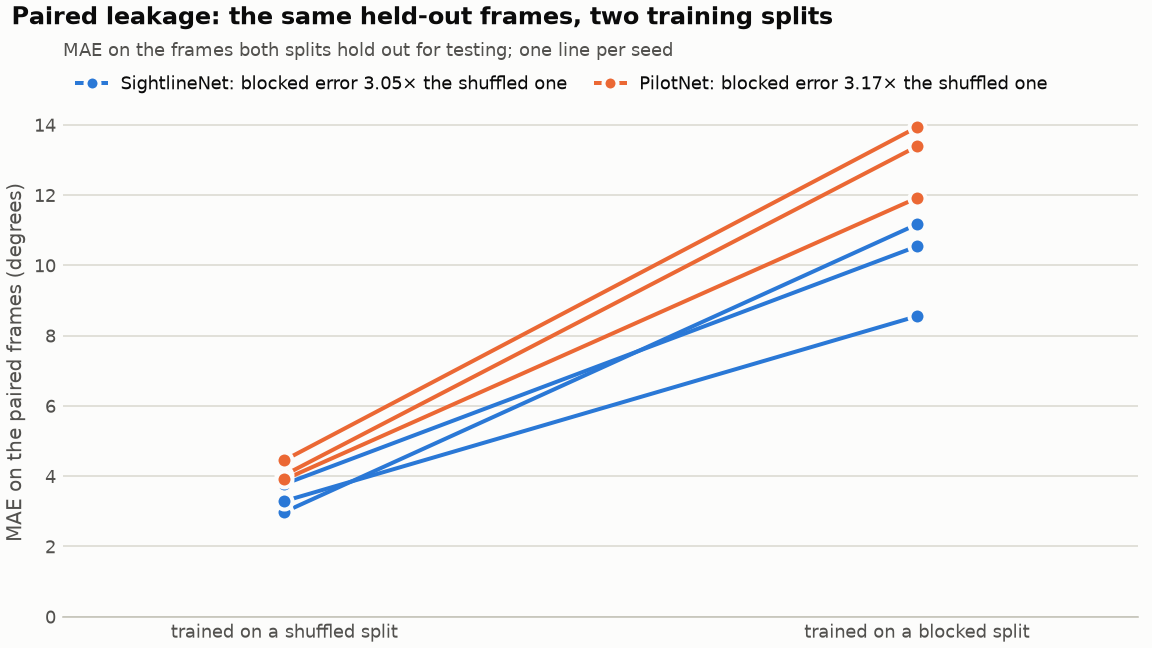

In [5]:
rows = []
for model, entry in summary["paired_leakage"].items():
    for p in entry["per_seed"]:
        rows.append([LABEL[model], p["seed"], f"{p['n']:,}", f"{p['shuffled_mae_deg']:.3f}",
                     f"{p['blocked_mae_deg']:.3f}", f"{p['ratio']:.3f}", f"{p['difference_deg']:.2f}",
                     f"{p['zero_mae_deg']:.2f}"])
table(["model", "seed", "paired frames", "trained on shuffled frames", "trained on blocked frames",
       "blocked ÷ shuffled", "blocked − shuffled (deg)", "always straight ahead"], rows)
for model, entry in summary["paired_leakage"].items():
    print(f"{LABEL[model]}: on identical frames the blocked-split error is {pm(entry['ratio'])} times the "
          f"shuffled-split error (per seed: {per_seed(entry['ratio'])}); "
          f"MAE {pm(entry['shuffled_mae_deg'])} vs {pm(entry['blocked_mae_deg'])} deg")

# identical frames: each seed's shuffled and blocked reports name the same frames by digest
compared = [(report(model, "leaky", p["seed"])["paired"]["frames_sha256"],
             report(model, "blocked", p["seed"])["paired"]["frames_sha256"])
            for model, entry in summary["paired_leakage"].items() for p in entry["per_seed"]]
assert compared, "no paired scores to compare"
same = all(shuffled == blocked for shuffled, blocked in compared)
first = {report(model, protocol, leakage["seed"])["paired"]["frames_sha256"]
         for model in summary["paired_leakage"] for protocol in ("leaky", "blocked")}
print(f"each seed's two models were scored on the same frames: {same} ({len(compared)} pairs of run reports)")
print(f"seed {leakage['seed']}'s paired frames are the ones reports/leakage.json analyses: "
      f"{first == {leakage['paired']['frames_sha256']}}")
show(figures.draw(summary, "paired-leakage.png"))

On identical frames, the model trained on shuffled frames scores an error several times smaller than
the model trained on blocked frames, for both architectures. The frames are the same; only what each
model saw around them in training differs. That ratio is how much a shuffled split flatters a steering
model on this drive.

## What each split's own score promises

A natural guess is that a model trained on shuffled frames is simply a worse model. Another day can test
that guess, one model at a time. The table sets each model's score on its own test split, the number its
split would report, beside its error on another day. Below the figure, the models that the shuffled split
and the blocked split train are compared on another day, seed by seed.

| model | trained on the split | its own test MAE | another-day MAE | another day ÷ own test | another-day skill |
| --- | --- | --- | --- | --- | --- |
| SightlineNet | shuffled | 2.90 ± 0.09 | 7.96 ± 0.13 | 2.74 | 0.487 ± 0.008 |
| SightlineNet | blocked | 10.24 ± 0.68 | 10.64 ± 1.30 | 1.04 | 0.315 ± 0.084 |
| SightlineNet | later in the drive | 6.18 ± 0.25 | 8.76 ± 0.38 | 1.42 | 0.435 ± 0.025 |
| PilotNet | shuffled | 4.01 ± 0.21 | 21.75 ± 2.24 | 5.43 | -0.401 ± 0.144 |
| PilotNet | blocked | 12.94 ± 0.16 | 19.28 ± 1.22 | 1.49 | -0.242 ± 0.079 |
| PilotNet | later in the drive | 13.63 ± 4.14 | 18.23 ± 2.64 | 1.34 | -0.174 ± 0.170 |
| SightlineNet, single frame | blocked | 11.42 ± 0.54 | 15.23 ± 0.66 | 1.33 | 0.019 ± 0.042 |

SightlineNet trained on shuffled frames: own test 2.90 ± 0.09 deg, another day 7.96 ± 0.13 deg
SightlineNet trained on blocked frames:  own test 10.24 ± 0.68 deg, another day 10.64 ± 1.30 deg
always straight ahead on another day: 15.52 deg


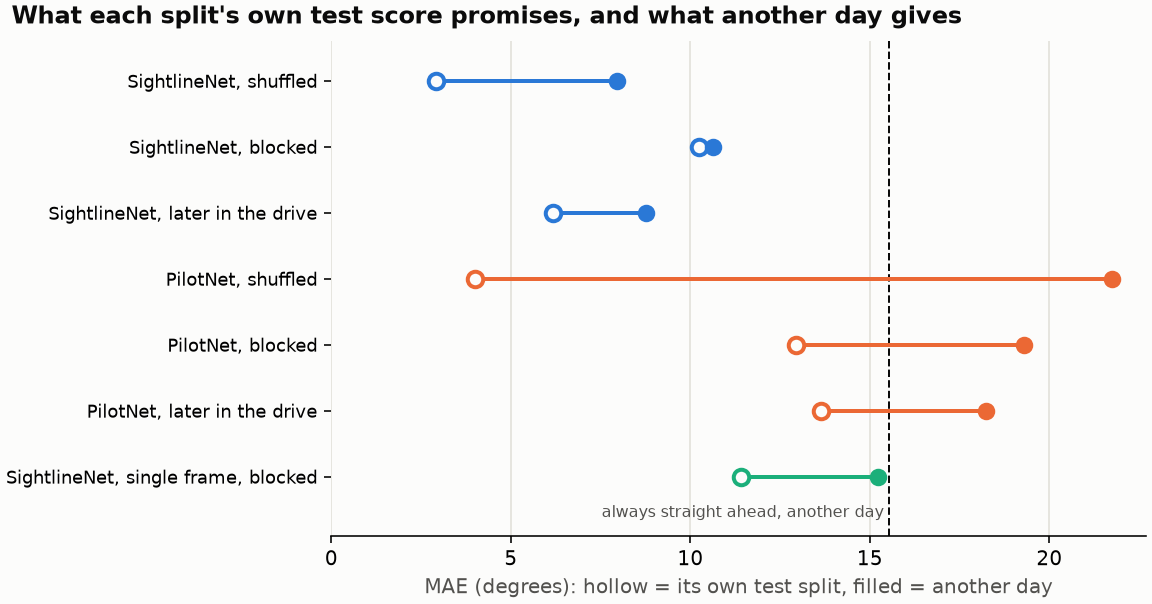

| model | seed | another-day MAE, trained on shuffled frames | trained on blocked frames | shuffled − blocked (deg) | always straight ahead |
| --- | --- | --- | --- | --- | --- |
| SightlineNet | 0 | 8.05 | 12.14 | -4.09 | 15.52 |
| SightlineNet | 1 | 7.81 | 10.01 | -2.20 | 15.52 |
| SightlineNet | 2 | 8.02 | 9.77 | -1.75 | 15.52 |
| PilotNet | 0 | 21.66 | 20.51 | +1.15 | 15.52 |
| PilotNet | 1 | 19.56 | 19.28 | +0.28 | 15.52 |
| PilotNet | 2 | 24.03 | 18.07 | +5.97 | 15.52 |

SightlineNet: the model trained on shuffled frames is worse on another day in 0 of 3 seeds; above always straight ahead in 0 of 3 seeds when trained on shuffled frames, 0 of 3 when trained on blocked frames
PilotNet: the model trained on shuffled frames is worse on another day in 3 of 3 seeds; above always straight ahead in 3 of 3 seeds when trained on shuffled frames, 3 of 3 when trained on blocked frames


In [6]:
def promise_gap(g):
    # the error on another day over the split's own test error: 1 would mean the score kept its promise
    return g["cross_mae_deg"]["mean"] / g["test_mae_deg"]["mean"]


order = sorted(summary["groups"].items(), key=lambda item: (list(LABEL).index(item[1]["model"]),
                                                          list(RUNG).index(item[1]["protocol"])))
rows = []
for key, g in order:
    model, protocol = key.split("/")
    rows.append([LABEL[model], RUNG[protocol], pm(g["test_mae_deg"]), pm(g["cross_mae_deg"]),
                 f"{promise_gap(g):.2f}", pm(g["cross_skill"], 3)])
table(["model", "trained on the split", "its own test MAE", "another-day MAE", "another day ÷ own test",
       "another-day skill"], rows)
twin, honest = group("sightlinenet", "leaky"), group("sightlinenet", "blocked")
print(f"SightlineNet trained on shuffled frames: own test {pm(twin['test_mae_deg'])} deg, "
      f"another day {pm(twin['cross_mae_deg'])} deg")
print(f"SightlineNet trained on blocked frames:  own test {pm(honest['test_mae_deg'])} deg, "
      f"another day {pm(honest['cross_mae_deg'])} deg")
print(f"always straight ahead on another day: {honest['cross_zero_mae_deg']:.2f} deg")

fig = Figure(figsize=(8.0, 4.2), dpi=figures.DPI, facecolor=figures.SURFACE, layout="constrained")
ax = fig.add_subplot()
ax.set_facecolor(figures.SURFACE)
for y, (key, g) in enumerate(order):
    model, protocol = key.split("/")
    own, other = g["test_mae_deg"]["mean"], g["cross_mae_deg"]["mean"]
    ax.plot([own, other], [y, y], color=figures.MODEL_COLOURS[model], linewidth=2, zorder=2)
    ax.scatter([own], [y], s=60, facecolors=figures.SURFACE, edgecolors=figures.MODEL_COLOURS[model], linewidths=2, zorder=3)
    ax.scatter([other], [y], s=60, color=figures.MODEL_COLOURS[model], zorder=3)
ax.axvline(honest["cross_zero_mae_deg"], color=figures.INK, linewidth=1, linestyle="--", zorder=1)
ax.text(honest["cross_zero_mae_deg"], len(order) - 0.45, "always straight ahead, another day ", fontsize=8,
        color=figures.INK_SECONDARY, va="center", ha="right")
ax.set_yticks(range(len(order)), labels=[f"{LABEL[k.split('/')[0]]}, {RUNG[k.split('/')[1]]}" for k, _ in order], fontsize=9)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.set_xlabel("MAE (degrees): hollow = its own test split, filled = another day", color=figures.INK_SECONDARY)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color=figures.GRID)
ax.set_axisbelow(True)
fig.suptitle("What each split's own test score promises, and what another day gives", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=figures.INK)
show(fig)

# what the shuffled split and the blocked split each train, seed by seed, scored on another day
rows, worse, above = [], {}, {}
for model in ("sightlinenet", "pilotnet"):
    shuffled, blocked = group(model, "leaky"), group(model, "blocked")
    assert shuffled["seeds"] == blocked["seeds"]
    straight = blocked["cross_zero_mae_deg"]
    pairs = list(zip(shuffled["cross_mae_deg"]["values"], blocked["cross_mae_deg"]["values"]))
    assert pairs and len(pairs) == len(blocked["seeds"]), f"{model}: no seeds to compare"
    for seed, (s, b) in zip(blocked["seeds"], pairs):
        rows.append([LABEL[model], seed, f"{s:.2f}", f"{b:.2f}", f"{s - b:+.2f}", f"{straight:.2f}"])
    worse[model] = sum(s > b for s, b in pairs)
    above[model] = (sum(s > straight for s, _ in pairs), sum(b > straight for _, b in pairs), len(pairs))
table(["model", "seed", "another-day MAE, trained on shuffled frames", "trained on blocked frames",
       "shuffled − blocked (deg)", "always straight ahead"], rows)
for model, (shuffled_above, blocked_above, n) in above.items():
    print(f"{LABEL[model]}: the model trained on shuffled frames is worse on another day in {worse[model]} of {n} seeds; "
          f"above always straight ahead in {shuffled_above} of {n} seeds when trained on shuffled frames, "
          f"{blocked_above} of {n} when trained on blocked frames")

# what the text below says: for both models the blocked split's score sits closer to the another-day error
# than the shuffled split's; SightlineNet's model trained on shuffled frames is never worse on another day,
# PilotNet's always is, and neither of PilotNet's two beats steering straight ahead there
assert all(promise_gap(group(model, "blocked")) < promise_gap(group(model, "leaky")) for model in ("sightlinenet", "pilotnet"))
assert worse["sightlinenet"] == 0
assert worse["pilotnet"] == above["pilotnet"][0] == above["pilotnet"][1] == above["pilotnet"][2]

The tables show two things. For both models, the shuffled split's own score promises far more than the
model delivers on another day, and the blocked split's score sits much closer to what the model does there:
compare the ratio column.

Whether a shuffled split also trains a worse model depends on the model. For SightlineNet, the model the
page compares, it does not: the one trained on shuffled frames is not worse on another day than the one
trained on blocked frames, in any seed, so for SightlineNet the shuffled split's defect is the score it
reports, not the model it trains. For PilotNet it does: the one trained on shuffled frames is worse on
another day than the one trained on blocked frames in every seed, by a margin that varies a good deal from
seed to seed, and neither of the two beats steering straight ahead there.

## Baselines

Four predictors that use no camera at all, on the shipped model's own splits. Always straight ahead answers
zero; the training mean answers the training set's mean angle; repeat-last copies the human's angle on
the previous frame; extrapolate continues the human's last two angles. The last two read the human's own
recent steering, which the model never sees, so they are not competitors: they show how little the angle
changes from one frame to the next, the closeness that a shuffled split hands to a model.

In [7]:
r = runs[shipped["run"]]
rows = []
for split, title in (("val", "validation"), ("test", "test"), ("cross_drive", "another day")):
    s, b = r[split], r[split]["baselines"]
    rows.append([title, f"{s['n']:,}", f"{s['model']['mae_deg']:.2f}", f"{b['zero']['mae_deg']:.2f}",
                 f"{b['mean']['mae_deg']:.2f}", f"{b['zoh']['mae_deg']:.2f}", f"{b['extrap']['mae_deg']:.2f}",
                 f"{s['pearson_r']:.3f}", f"{s['sign_agreement']:.1%}"])
table(["split", "frames", "shipped model", "always straight ahead", "training mean", "repeat-last (reads the human)",
       "extrapolate (reads the human)", "Pearson r", "sign agreement"], rows)
print(f"sign agreement: the share of frames steered at least {cutoffs['sign_min_abs_deg']:g} deg either way on which the "
      "model turns the wheel the same way as the human")
t = r["test"]["model"]


# the tolerances, as the summary records them; within_key names the field of each share
tolerances = cutoffs["tolerances_deg"]
assert sorted(within_key(x) for x in tolerances) == sorted(field for field in t if field.startswith("within_"))
print("test frames within " + " / ".join(f"{x:g}" for x in tolerances) + " deg of the human: "
      + " / ".join(f"{t[within_key(x)]:.1%}" for x in tolerances)
      + f"; median error {t['medae_deg']:.2f} deg, RMSE {t['rmse_deg']:.2f} deg")
smooth = r["test"]["smoothness"]
print(f"frame-to-frame change on the test split: model {smooth['model']['mean_abs_step_deg']:.2f} deg, "
      f"human {smooth['human']['mean_abs_step_deg']:.2f} deg on average")

| split | frames | shipped model | always straight ahead | training mean | repeat-last (reads the human) | extrapolate (reads the human) | Pearson r | sign agreement |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| validation | 6,000 | 7.15 | 14.48 | 14.35 | 0.54 | 0.65 | 0.736 | 93.4% |
| test | 6,000 | 10.12 | 17.48 | 17.84 | 0.59 | 0.69 | 0.662 | 93.3% |
| another day | 45,404 | 9.77 | 15.52 | 15.47 | 0.51 | 0.49 | 0.611 | 89.6% |

sign agreement: the share of frames steered at least 5 deg either way on which the model turns the wheel the same way as the human
test frames within 1.5 / 5 / 15 deg of the human: 18.4% / 54.8% / 86.6%; median error 4.55 deg, RMSE 25.14 deg
frame-to-frame change on the test split: model 2.44 deg, human 0.59 deg on average


## Error by steering regime

Most driving is close to straight, so one average hides the turns. The blocked test frames are split by
the human's angle into straight, gentle and sharp, and the balanced MAE weighs the three equally. Each
model is shown with its seed of lowest validation error.

| regime | frames | PilotNet (seed 1) | SightlineNet (seed 2) | SightlineNet, single frame (seed 2) | always straight ahead |
| --- | --- | --- | --- | --- | --- |
| straight, under 5 deg either way | 2,731 | 5.74 | 6.09 | 6.30 | 2.76 |
| gentle, 5 to 30 deg | 2,416 | 8.87 | 5.52 | 8.55 | 12.60 |
| sharp, 30 deg or more | 853 | 48.21 | 36.05 | 40.24 | 78.41 |
| balanced (the three weighted equally) |  | 20.94 | 15.89 | 18.36 | 31.26 |

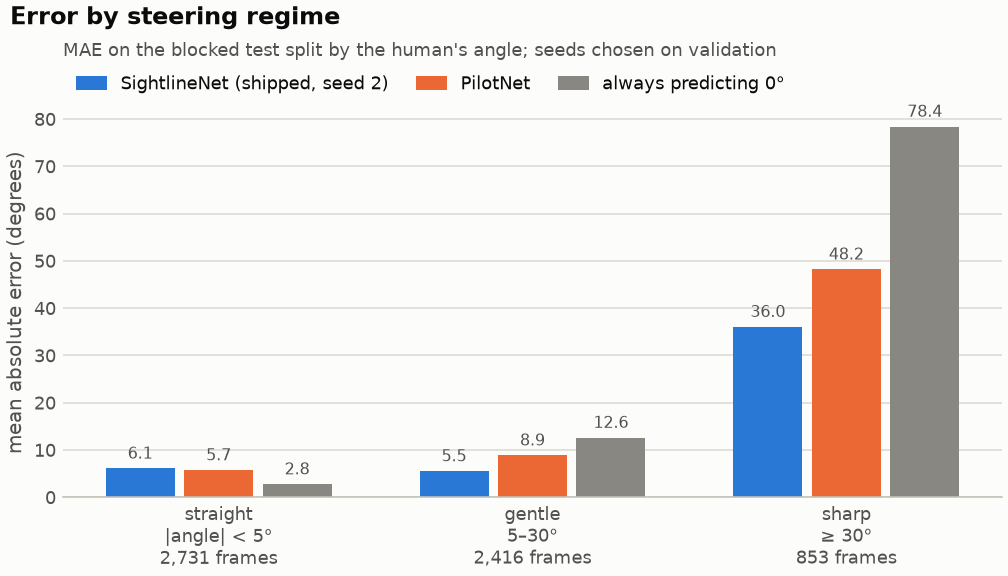

In [8]:
regimes = summary["regimes"]
low, high = cutoffs["regime_bins_deg"]
names = {"straight": f"straight, under {low:g} deg either way", "gentle": f"gentle, {low:g} to {high:g} deg",
         "sharp": f"sharp, {high:g} deg or more"}
columns = [(f"{LABEL[model]} (seed {entry['seed']})", entry["regimes"]) for model, entry in regimes["models"].items()]
columns.append(("always straight ahead", regimes["zero"]))
rows = [[names[k], f"{regimes['zero'][k]['n']:,}"] + [f"{values[k]['mae_deg']:.2f}" for _, values in columns]
        for k in ("straight", "gentle", "sharp")]
rows.append(["balanced (the three weighted equally)", ""] + [f"{values['balanced_mae_deg']:.2f}" for _, values in columns])
table(["regime", "frames"] + [title for title, _ in columns], rows)
show(figures.draw(summary, "regimes.png"))

On straight road, always steering straight ahead is better than every model; the models earn their
keep in the turns, where steering straight ahead fails worst. Sharp turns remain the hardest part for every model.

## What the earlier frame adds

SightlineNet sees the current frame and an earlier one from the same camera, stacked together; the single
frame SightlineNet is the same network, trained with the same recipe, on the current frame alone. The
difference between them is what the motion between two frames adds.

In [9]:
two, one = group("sightlinenet", "blocked"), group("sightlinenet-1f", "blocked")
rows = [
    ["validation MAE", pm(two["val_mae_deg"]), pm(one["val_mae_deg"])],
    ["test MAE", pm(two["test_mae_deg"]), pm(one["test_mae_deg"])],
    ["test Pearson r", pm(two["test_r"], 3), pm(one["test_r"], 3)],
    ["test skill", pm(two["test_skill"], 3), pm(one["test_skill"], 3)],
    ["another-day MAE", pm(two["cross_mae_deg"]), pm(one["cross_mae_deg"])],
    ["another-day Pearson r", pm(two["cross_r"], 3), pm(one["cross_r"], 3)],
    ["another-day skill", pm(two["cross_skill"], 3), pm(one["cross_skill"], 3)],
]
table(["trained on the blocked split", f"{LABEL['sightlinenet']} (two frames)", LABEL["sightlinenet-1f"]], rows)
print(f"another-day skill over always straight ahead: two frames {pm(two['cross_skill'], 3)}, "
      f"one frame {pm(one['cross_skill'], 3)} (per seed: {per_seed(one['cross_skill'], 3)})")

| trained on the blocked split | SightlineNet (two frames) | SightlineNet, single frame |
| --- | --- | --- |
| validation MAE | 7.69 ± 0.66 | 10.28 ± 0.10 |
| test MAE | 10.24 ± 0.68 | 11.42 ± 0.54 |
| test Pearson r | 0.666 ± 0.009 | 0.652 ± 0.030 |
| test skill | 0.414 ± 0.039 | 0.347 ± 0.031 |
| another-day MAE | 10.64 ± 1.30 | 15.23 ± 0.66 |
| another-day Pearson r | 0.603 ± 0.077 | 0.476 ± 0.027 |
| another-day skill | 0.315 ± 0.084 | 0.019 ± 0.042 |

another-day skill over always straight ahead: two frames 0.315 ± 0.084, one frame 0.019 ± 0.042 (per seed: 0.068, -0.003, -0.008)


On the blocked test split both versions clearly beat steering straight ahead. On another day the
single frame model is level with steering straight ahead, while the two-frame model keeps a clear margin:
the motion between two frames is the cue that carries over to another road on another day.

One caveat goes with it. A model that sees motion partly perceives a turn already under way, through the
car's own rotation, rather than deciding to turn. Sightline estimates the steering angle from video,
scored frame by frame on recorded drives; it is not a driving policy, and nothing here was tested in
closed loop.

## The standard-recipe PilotNet

A PilotNet trained with the widely copied recipe: a shuffled frame split, mean squared error in radians
and an arctangent output head that cannot reach half a turn. Its weights were trained on `drive2017` and
are not part of this repository; `sightline legacy` scores them on that drive, its own training drive,
and on the same `drive2018` test frames as the runs above, from a drive it never saw.

In [10]:
print(legacy["recipe"])
parity = legacy["port_parity"]
print(f"trained on {legacy['trained_on']}; the PyTorch port is within {parity['max_abs_diff_deg']:.1e} deg of the "
      f"TF1 graph on {parity['frames']} frames; scored on the {legacy['device']}")
titles = {
    f"{legacy['trained_on']}_all_seen": f"{legacy['trained_on']}, its own training drive (from frame {legacy['seen_first_frame']})",
    f"{TRAIN_DRIVE}_blocked_test": f"{TRAIN_DRIVE}, the blocked test frames",
    f"{TRAIN_DRIVE}_forward_test": f"{TRAIN_DRIVE}, the later-in-the-drive test frames",
}
rows = [[titles[key], f"{s['model']['n']:,}", f"{s['model']['mae_deg']:.2f}", f"{s['zero_mae_deg']:.2f}",
         f"{s['pearson_r']:.3f}", f"{s['regimes']['balanced_mae_deg']:.2f}"] for key, s in legacy["eval"].items()]
table(["frames scored", "frames", "MAE", "always straight ahead", "Pearson r", "balanced MAE"], rows)
assert legacy["splits"] == {k: report("sightlinenet", "blocked", 0)["splits"][k] for k in ("block", "firewall")}
blocked = legacy["eval"][f"{TRAIN_DRIVE}_blocked_test"]["model"]["mae_deg"]
print(f"on the blocked test frames (the same split settings as the runs): standard recipe {blocked:.2f} deg, "
      f"PilotNet {pm(group('pilotnet', 'blocked')['test_mae_deg'])} deg, "
      f"SightlineNet {pm(group('sightlinenet', 'blocked')['test_mae_deg'])} deg")
cap = legacy["atan_cap"]
(beyond,) = [field for field in cap if field.startswith("labels_beyond_")]  # the report names the limit: labels_beyond_180
print(f"largest |prediction|: {cap['max_abs_pred_deg']:.1f} deg; labels steered past {beyond.removeprefix('labels_beyond_')} deg, "
      "out of the head's reach: " + ", ".join(f"{drive} {c['n']} ({c['frac']:.2%})" for drive, c in sorted(cap[beyond].items())))

PilotNet in TensorFlow 1: shuffled 80/20 frame split, MSE in radians plus L2, atan output head limited to ±180°
trained on drive2017; the PyTorch port is within 2.2e-04 deg of the TF1 graph on 192 frames; scored on the cpu


| frames scored | frames | MAE | always straight ahead | Pearson r | balanced MAE |
| --- | --- | --- | --- | --- | --- |
| drive2017, its own training drive (from frame 2) | 45,404 | 4.48 | 15.52 | 0.948 | 6.80 |
| drive2018, the blocked test frames | 6,000 | 21.97 | 17.48 | 0.217 | 31.75 |
| drive2018, the later-in-the-drive test frames | 9,324 | 19.39 | 9.41 | 0.138 | 43.02 |

on the blocked test frames (the same split settings as the runs): standard recipe 21.97 deg, PilotNet 12.94 ± 0.16 deg, SightlineNet 10.24 ± 0.68 deg
largest |prediction|: 169.8 deg; labels steered past 180 deg, out of the head's reach: drive2017 223 (0.49%), drive2018 235 (0.37%)


On its own training drive the standard-recipe PilotNet looks excellent. On a drive it never saw, it is
worse than steering straight ahead on both test sets, and its arctangent head stops every prediction
short of half a turn, which both drives exceed.

## The models in the browser

The page runs the shipped model and its shuffled-split twin as ONNX graphs that return the steering angle
and the saliency map together. An export is kept only when onnxruntime reproduces the PyTorch outputs
within a fixed tolerance on every frame stack the page uses.

In [11]:
rows = []
for key, m in export["models"].items():
    p = m["parity"]
    rows.append([key, m["run"], f"{m['bytes']:,}", f"{p['frames']:,}", f"{p['max_angle_diff_deg']:.1e}",
                 f"{p['angle_tolerance_deg']:g}", f"{p['max_saliency_diff']:.1e}", f"{p['saliency_tolerance']:g}"])
table(["model", "run", "bytes", "frame stacks checked", "largest angle difference (deg)", "allowed",
       "largest saliency difference", "allowed"], rows)
assert export["models"]["sightline"]["run"] == summary["shipped"]["run"]
assert export["models"]["shuffled"]["run"] == summary["twin"]["run"]
print("the browser's models are the shipped run and its twin")

| model | run | bytes | frame stacks checked | largest angle difference (deg) | allowed | largest saliency difference | allowed |
| --- | --- | --- | --- | --- | --- | --- | --- |
| shuffled | drive2018_sightlinenet_leaky_s2 | 1,170,711 | 848 | 1.3e-04 | 0.0005 | 8.2e-06 | 0.0001 |
| sightline | drive2018_sightlinenet_blocked_s2 | 1,170,713 | 848 | 1.8e-04 | 0.0005 | 7.5e-06 | 0.0001 |

the browser's models are the shipped run and its twin
